# 5. Học không giám sát – Phân cụm bài báo theo chủ đề

**Mục tiêu:** nhóm bài theo nội dung, giảm các cụm chỉ phản ánh video/văn nói và cung cấp bằng chứng kiểm tra chất lượng cụm.

So sánh **TF-IDF gốc → LSA → K-Means** với **TF-IDF hướng chủ đề (unigram + bigram, lọc từ văn phong) → LSA → K-Means**. Cả hai giữ **100 chiều LSA** để tránh làm silhouette tăng chỉ vì giảm số chiều.

Nhãn `label` và `subject` chỉ dùng sau khi chốt mô hình. Các hàm nằm trong `topic_clustering.py`; bộ lọc ở đây chỉ dành cho phân cụm, không sửa dữ liệu hay mô hình phân loại.

In [1]:
from pathlib import Path
from itertools import combinations
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples
from scipy.stats import chi2_contingency

from topic_clustering import (
    TOPIC_STOP_WORDS, build_features, evaluate_labels, search_clusters,
    select_k, keyword_table, article_tables, fitted_pipeline, predict_topics,
)

SEED = 42
SEEDS = (42, 17, 93)
K_VALUES = (6, 8, 10, 12, 14)
N_INIT = 10
SAMPLE_SIZE = 3000
DIMENSIONS = 100
RESULTS_DIR = Path("results/clustering")
MODELS_DIR = Path("models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("data/processed/news_clean.csv", keep_default_na=False)
assert df["raw_id"].is_unique, "raw_id phải duy nhất để đối chiếu bài báo."
print(f"Đọc {len(df):,} bài. Chọn mô hình chỉ từ clean_text.")

Đọc 38,821 bài. Chọn mô hình chỉ từ clean_text.


## 1. Hai cách biểu diễn và tập so sánh chung

- **Baseline:** TF-IDF cũ, 20.000 đặc trưng unigram, `min_df=5`, `max_df=0.5`.
- **Hướng chủ đề:** tối đa 30.000 đặc trưng unigram + bigram, `min_df=10`, `max_df=0.4`; lọc stop-word tiếng Anh cùng danh sách cố định từ văn nói/định dạng như `say`, `get`, `video`, `watch`, `via`.
- Bigram như `north korea`, `supreme court` giữ ý nghĩa cụm từ. Bộ lọc là giả định thiết kế: `video`, `twitter`, `president` cũng có thể mang nội dung; danh sách được xuất để kiểm tra và thử nghiệm thêm.
- Bài không còn đặc trưng được ghi riêng, gán `cluster=-1`, không ép vào một chủ đề.

Hai mô hình dùng **cùng bài báo, cùng mẫu ngẫu nhiên cố định và cùng không gian TF-IDF hướng chủ đề trước LSA** để tính cosine silhouette. Silhouette Euclidean sau LSA được báo riêng; không so hai loại điểm như cùng một thước đo.

Giữ **float64 như notebook gốc** ở cả hai cấu hình. Thử nghiệm float32 làm thay đổi độ ổn định ở một số K; các bảng của lần thử đó được lưu riêng trong `results/clustering/precision_float32/`, không trộn vào kết quả cuối.

In [2]:
with threadpool_limits(limits=4):
    baseline_features = build_features(df["clean_text"], topic_focused=False,
                                       seed=SEED, dimensions=DIMENSIONS)
    topic_features = build_features(df["clean_text"], topic_focused=True,
                                    seed=SEED, dimensions=DIMENSIONS)

valid = baseline_features["valid"] & topic_features["valid"]
work = df.loc[valid].reset_index(drop=True)
excluded = df.loc[~valid, ["raw_id", "title"]].copy()
excluded["reason"] = "No TF-IDF features after filtering"
excluded.to_csv(RESULTS_DIR / "excluded_articles.csv", index=False)

X_base = baseline_features["dense"][valid]
X = topic_features["dense"][valid]
X_tfidf = topic_features["sparse"][valid]
sample_indices = np.sort(np.random.default_rng(SEED).choice(
    len(work), size=min(SAMPLE_SIZE, len(work)), replace=False))
reference_sample = X_tfidf[sample_indices]
work.iloc[sample_indices][["raw_id"]].to_csv(RESULTS_DIR / "evaluation_sample.csv", index=False)
(RESULTS_DIR / "topic_stop_words.txt").write_text("\n".join(TOPIC_STOP_WORDS), encoding="utf-8")

print(f"So sánh trên {len(work):,} bài; loại khỏi phân cụm {len(excluded)} bài không có đặc trưng.")
print(f"Mẫu đánh giá: {len(sample_indices):,} bài; LSA: {DIMENSIONS} chiều ở cả hai cấu hình.")
print("TF-IDF gốc:", baseline_features["sparse"].shape,
      "| TF-IDF hướng chủ đề:", topic_features["sparse"].shape)
print("Tỷ lệ phương sai LSA giữ lại:",
      {name: round(float(f["svd"].explained_variance_ratio_.sum()), 4)
       for name, f in [("baseline", baseline_features), ("topic", topic_features)]})

So sánh trên 38,820 bài; loại khỏi phân cụm 1 bài không có đặc trưng.
Mẫu đánh giá: 3,000 bài; LSA: 100 chiều ở cả hai cấu hình.
TF-IDF gốc: (38821, 20000) | TF-IDF hướng chủ đề: (38821, 30000)
Tỷ lệ phương sai LSA giữ lại: {'baseline': 0.1478, 'topic': 0.125}


## 2. Khảo sát K và độ ổn định

Mỗi K trong {6, 8, 10, 12, 14} chạy **3 seed**, mỗi seed `n_init=10`.

**Quy tắc khai báo trước:**
1. Giữ K có ARI ổn định giữa seed ≥ 0,75, cụm nhỏ nhất ≥ 1% và cụm lớn nhất ≤ 40% dữ liệu trong cả ba seed.
2. Tối đa hóa cosine silhouette trong TF-IDF chung; trong vùng chênh ≤ 0,001, ưu tiên ổn định cao hơn rồi K nhỏ hơn.
3. Giữ **đúng mô hình seed 42 đã đánh giá**, không fit lại với cấu hình khác.

ARI ổn định so các lần phân cụm với nhau, không dùng Fake/True. Inertia chỉ để tham khảo, không tự quyết định số chủ đề. Chương trình dừng nếu không K nào qua điều kiện.

K= 6: cosine=0.0099, stability=0.754


K= 8: cosine=0.0120, stability=0.986


K=10: cosine=0.0123, stability=0.989


K=12: cosine=0.0129, stability=0.719


K=14: cosine=0.0127, stability=0.706



Chọn K=10; mô hình cuối chính là candidate seed=42, n_init=10.


,Silhouette TF-IDF cosine,Silhouette TF-IDF std,Silhouette LSA Euclidean,Stability ARI,Min cluster share,Max cluster share,Inertia,Selected
K,,,,,,,,
6,0.00994,0.00044,0.04750,0.75419,0.03143,0.27635,28277.12551,False
8,0.01198,0.00001,0.05484,0.98586,0.03145,0.21607,27399.59278,False
10,0.01234,0.00000,0.05788,0.98893,0.03145,0.19438,26688.65864,True
12,0.01286,0.00015,0.05953,0.71919,0.03063,0.18532,26111.69661,False
14,0.01272,0.00013,0.06168,0.70625,0.02092,0.18336,25605.61244,False


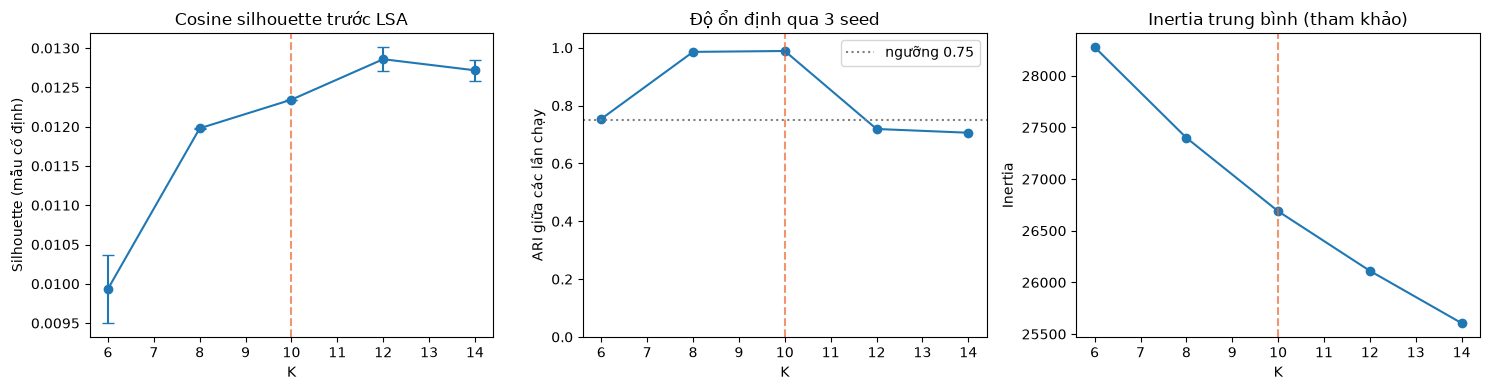

In [3]:
with threadpool_limits(limits=4):
    k_scores, k_runs, candidate_models = search_clusters(
        X, reference_sample, sample_indices, k_values=K_VALUES,
        seeds=SEEDS, n_init=N_INIT)
K = select_k(k_scores)
kmeans = candidate_models[K]
work["cluster"] = kmeans.labels_

k_scores["Selected"] = k_scores.index == K
k_scores.to_csv(RESULTS_DIR / "k_selection.csv")
k_runs.to_csv(RESULTS_DIR / "k_runs.csv", index=False)
print(f"\nChọn K={K}; mô hình cuối chính là candidate seed={SEED}, n_init={N_INIT}.")
display(k_scores.round(5))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].errorbar(k_scores.index, k_scores["Silhouette TF-IDF cosine"],
                 yerr=k_scores["Silhouette TF-IDF std"], marker="o", capsize=4)
axes[0].set(title="Cosine silhouette trước LSA", xlabel="K", ylabel="Silhouette (mẫu cố định)")
axes[1].plot(k_scores.index, k_scores["Stability ARI"], marker="o")
axes[1].axhline(.75, color="grey", ls=":", label="ngưỡng 0.75")
axes[1].set(title="Độ ổn định qua 3 seed", xlabel="K", ylabel="ARI giữa các lần chạy", ylim=(0, 1.05))
axes[1].legend()
axes[2].plot(k_scores.index, k_scores["Inertia"], marker="o")
axes[2].set(title="Inertia trung bình (tham khảo)", xlabel="K", ylabel="Inertia")
for ax in axes:
    ax.axvline(K, color="#eb6834", ls="--", alpha=.7)
plt.tight_layout()
fig.savefig(RESULTS_DIR / "k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. So sánh với cấu hình cũ

Baseline chạy lại ở K=10 trên cùng tập bài, ba seed và `n_init=10`. So thêm cấu hình hướng chủ đề **giữ K=10** để phân biệt ảnh hưởng của biểu diễn với ảnh hưởng của đổi K.

`comparison.csv` ghi điểm của mô hình seed 42 thực tế; `k_selection.csv` ghi trung bình và độ lệch giữa seed. Số cũ 0,057 dùng mẫu 5.000 bài và không gian cũ, nên không dùng trực tiếp để tính mức tăng của thước đo chung mới.

In [4]:
with threadpool_limits(limits=4):
    baseline_models = [KMeans(n_clusters=10, n_init=N_INIT, random_state=seed).fit(X_base)
                       for seed in SEEDS]
    baseline_stability = np.mean([adjusted_rand_score(a.labels_, b.labels_)
                                  for a, b in combinations(baseline_models, 2)])
    comparison_rows = []
    comparisons = [
        ("Baseline TF-IDF gốc, K=10", X_base, baseline_models[0], baseline_stability),
        ("TF-IDF chủ đề, K=10", X, candidate_models[10], k_scores.loc[10, "Stability ARI"]),
        (f"Mô hình chọn, K={K}", X, kmeans, k_scores.loc[K, "Stability ARI"]),
    ]
    for name, vectors, model, stability in comparisons:
        comparison_rows.append({"Model": name, "K": model.n_clusters,
                                **evaluate_labels(vectors, reference_sample, model.labels_, sample_indices),
                                "Stability ARI": stability})
comparison = pd.DataFrame(comparison_rows).set_index("Model")
comparison.to_csv(RESULTS_DIR / "comparison.csv")
final_metrics = comparison.iloc[[-1]].copy()
final_metrics.to_csv(RESULTS_DIR / "final_metrics.csv")
display(comparison.round(5))
delta = comparison.iloc[-1]["Silhouette TF-IDF cosine"] - comparison.iloc[0]["Silhouette TF-IDF cosine"]
display(Markdown(f"Chênh cosine silhouette trong **cùng không gian TF-IDF**: **{delta:+.5f}**. "
                 "Điểm tuyệt đối thấp vẫn cho thấy chủ đề chồng lấn; tăng điểm không đủ để khẳng định mọi cụm đúng chủ đề."))

,K,Silhouette TF-IDF cosine,Silhouette LSA Euclidean,Min cluster share,Max cluster share,Stability ARI
Model,,,,,,
"Baseline TF-IDF gốc, K=10",10,0.01184,0.05706,0.03145,0.20726,0.98528
"TF-IDF chủ đề, K=10",10,0.01234,0.05791,0.03148,0.19410,0.98893
"Mô hình chọn, K=10",10,0.01234,0.05791,0.03148,0.19410,0.98893


Chênh cosine silhouette trong **cùng không gian TF-IDF**: **+0.00050**. Điểm tuyệt đối thấp vẫn cho thấy chủ đề chồng lấn; tăng điểm không đủ để khẳng định mọi cụm đúng chủ đề.

## 4. Từ khóa có trọng số và bài đại diện

Xếp từ khóa theo **TF-IDF trung bình × log(1 + lift)**; lift là tỷ lệ TF-IDF trung bình trong cụm so với toàn bộ dữ liệu. Chỉ giữ từ xuất hiện trong ≥ 1% bài của cụm để giảm từ quá hiếm. CSV lưu cả trọng số và tỷ lệ bài chứa từ.

Mỗi cụm có ba bài gần tâm nhất để kiểm tra nội dung. Tên gợi ý từ ba từ khóa chỉ hỗ trợ đọc; cần đối chiếu bài đại diện trước khi đặt tên chủ đề chính thức.

In [5]:
terms = topic_features["tfidf"].get_feature_names_out()
keywords = keyword_table(X_tfidf, terms, work["cluster"].to_numpy())
articles, representatives, boundary = article_tables(work, X, kmeans)
summary = work.groupby("cluster").size().to_frame("Số bài")
summary["% dữ liệu"] = summary["Số bài"] / len(work) * 100
summary["Chủ đề gợi ý"] = keywords[keywords["rank"] <= 3].groupby("cluster")["term"].agg(" / ".join)
summary["Từ khóa"] = keywords[keywords["rank"] <= 10].groupby("cluster")["term"].agg(", ".join)
summary["Bài gần tâm nhất"] = representatives[representatives["rank"] == 1].set_index("cluster")["title"]
keywords.to_csv(RESULTS_DIR / "cluster_keywords.csv", index=False)
representatives.to_csv(RESULTS_DIR / "representative_articles.csv", index=False)
boundary.to_csv(RESULTS_DIR / "boundary_articles.csv", index=False)

assignments = df[["raw_id", "title"]].merge(
    articles.drop(columns="title"), on="raw_id", how="left", validate="one_to_one")
assignments["cluster"] = assignments["cluster"].fillna(-1).astype(int)
assignments.to_csv(RESULTS_DIR / "cluster_articles.csv", index=False)
summary.to_csv(RESULTS_DIR / "cluster_summary.csv")
with pd.option_context("display.max_colwidth", 110):
    display(summary.round(2))
    display(representatives[["cluster", "rank", "raw_id", "title", "distance_to_center"]])

,Số bài,% dữ liệu,Chủ đề gợi ý,Từ khóa,Bài gần tâm nhất
cluster,,,,,
0,6392,16.47,iran / syria / military,"iran, syria, military, al, islamic, islamic state, syrian, saudi, turkey, militant",Sunnistan: US and Allied ‘Safe Zone’ Plan to Take Territorial Booty in Northern Syria
1,7535,19.41,woman / america / racist,"woman, america, racist, tweet, black, white, american, right, obama, love",Trump: The First President to Turn Postmodernism Against Itself
2,6345,16.34,court / federal / company,"court, federal, company, administration, executive, supreme court, supreme, department, law, order",THE LIST OF OBAMA’S HISTORIC FIRSTS AKA HOW CHICAGO POLITICS CORRUPTED WASHINGTON EVEN MORE
3,2431,6.26,clinton / hillary / hillary clinton,"clinton, hillary, hillary clinton, email, server, clinton foundation, campaign, clinton campaign, benghazi...",Hillary Clinton Broke The Internet With Trump Trolling Site
4,3653,9.41,candidate / cruz / republican,"candidate, cruz, republican, voter, presidential, poll, election, sander, ted cruz, ted",LOVE HIM OR HATE HIM…HERE ARE 7 WAYS TRUMP HELPS THE SPINELESS GOP
5,2925,7.53,police / officer / arrest,"police, officer, arrest, police officer, shoot, gun, cop, kill, man, suspect",BREAKING: TEXAS COP STABBED 14 TIMES By Man Who “had a desire to kill a police officer”
6,2774,7.15,tax / obamacare / healthcare,"tax, obamacare, healthcare, senate, republican, legislation, repeal, house, insurance, pass",Senate Republicans tie tax plan to repeal of key Obamacare mandate
7,2842,7.32,russia / russian / intelligence,"russia, russian, intelligence, putin, comey, fbi, investigation, moscow, flynn, mueller",WOW: Intercepted Communications Implicate Three Top Trump Advisors In Plot With Russia
8,1222,3.15,korea / north korea / north,"korea, north korea, north, korean, missile, nuclear, pyongyang, north korean, south korea, china","U.S. challenged by rising North Korea tensions, Russia urges calm"


,cluster,rank,raw_id,title,distance_to_center
17877,0,1,22695,Sunnistan: US and Allied ‘Safe Zone’ Plan to Take Territorial Booty in Northern Syria,0.711488
17786,0,2,22604,EXPOSED: How US-Backed War on Syria Helped ISIS to Expand Their Operations,0.720968
17496,0,3,22314,BREAKING: At Least 14 US Coalition Military Officers Captured by Syrian Special Forces in East Aleppo Bunker,0.722508
17432,1,1,22250,Trump: The First President to Turn Postmodernism Against Itself,0.570626
4801,1,2,4801,Legendary Humorist And Radio Host HAMMERS Trump In Devastating Open Letter,0.586092
15646,1,3,15665,WILL TAYLOR SWIFT “Bestie” AND LEFTIST WHO LIED ABOUT BEING RAPED BY A REPUBLICAN Ruin Her Wholesome Image?,0.606273
15809,2,1,15828,THE LIST OF OBAMA’S HISTORIC FIRSTS AKA HOW CHICAGO POLITICS CORRUPTED WASHINGTON EVEN MORE,0.607053
9196,2,2,9197,WATCH: “IT’S THE MOST WONDERFUL TIME OF THE YEAR”…Trump Style,0.630289
17195,2,3,22013,What is The Deep State?,0.641303
5384,3,1,5384,Hillary Clinton Broke The Internet With Trump Trolling Site,0.526991


## 5. Bài ở ranh giới và hình chiếu minh họa

- `boundary_margin` là khoảng cách tới tâm gần thứ hai trừ khoảng cách tới tâm được gán. Margin nhỏ nghĩa là gần ranh giới; **không phải xác suất hay độ tin cậy đã hiệu chuẩn**.
- PCA 2D chỉ minh họa trên mẫu đánh giá. Không phân cụm trên hình 2D hoặc dùng độ tách trên hình làm bằng chứng chất lượng.
- Phân bố silhouette theo cụm giúp phát hiện cụm còn lẫn; giá trị âm nghĩa là bài gần cụm khác hơn theo khoảng cách trung bình.

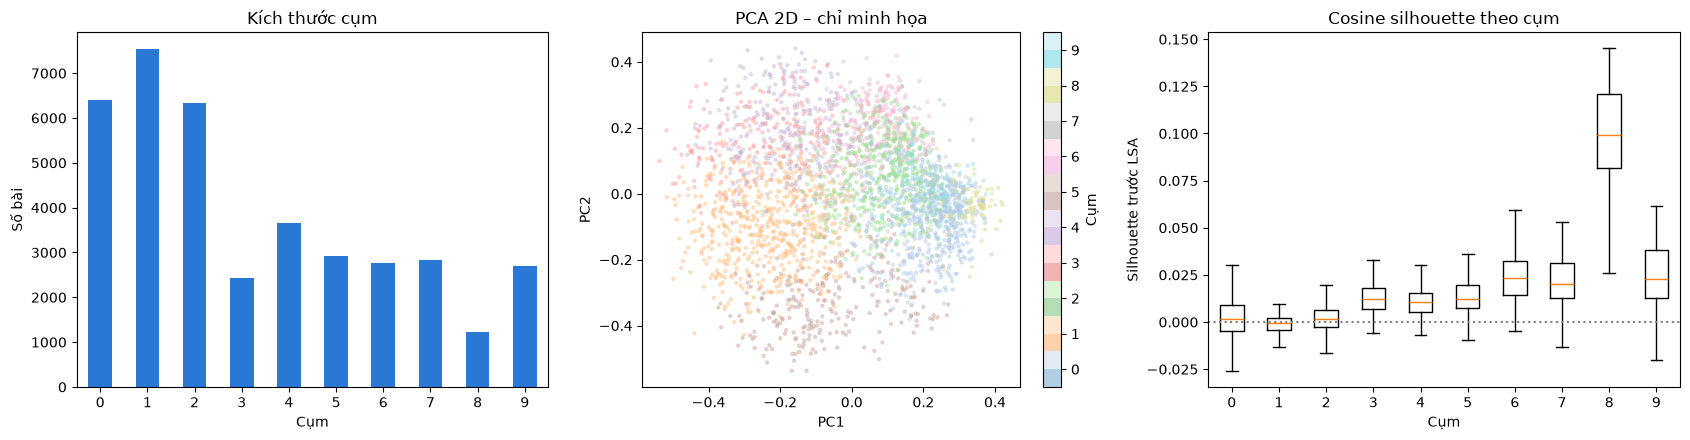

Các bài có margin thấp, cần đọc để kiểm tra ranh giới:


,cluster,raw_id,title,boundary_margin
7297,0,7297,Fox News Military Expert Hilariously Destroys Trump’s and Cruz’s Strategies Against ISIS,0.000006
14101,0,14114,NEIL CAVUTO AND YOUNG COMMIE CLASH: “The capitalist system is illegitimate” [Video],0.000036
9416,1,9418,AWESOME! President Trump Gives Fatherly Advice About ‘The Road of Life’ to UCLA Basketball Players,0.000298
17096,1,21896,SHOCKING: UNIV OF HAWAII RECRUITS GIRLS AS YOUNG AS 14 YEARS OLD FOR 2ND TRIMESTER ABORTION EXPERIMENTS,0.000314
13346,2,13359,YOU LIE! OBAMA SECRETLY PAID $400 MILLION Ransom To IRAN For Release Of Americans…BRAGGED About “Diplomati...,0.000011
38510,2,44570,Hong Kong scraps 24-hour BBC World Service radio channel despite criticism,0.000036
4814,3,4814,IRS Slams Trump Foundation For Breaking The Law,0.000018
9128,3,9129,JUST IN: PRESIDENT TRUMP BLASTS “Retiring” FBI Deputy Director Andrew McCabe and “’Leakin’ James Comey” Af...,0.000253
6277,4,6277,Donald Trump Humiliates Chris Christie AGAIN And It’s Worse Than Ever Before (VIDEO),0.000140
7628,4,7628,New Republican SCOTUS Tactic: Who Needs 9 Justices Anyway?,0.000144


In [6]:
with threadpool_limits(limits=4):
    projection = PCA(n_components=2, random_state=SEED).fit_transform(X[sample_indices])
    sample_silhouette = silhouette_samples(reference_sample, kmeans.labels_[sample_indices], metric="cosine")
sample_labels = kmeans.labels_[sample_indices]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
summary["Số bài"].plot.bar(ax=axes[0], color="#2a78d6", rot=0)
axes[0].set(title="Kích thước cụm", xlabel="Cụm", ylabel="Số bài")
scatter = axes[1].scatter(projection[:, 0], projection[:, 1], c=sample_labels,
                          cmap="tab20", s=5, alpha=.35, vmin=-.5, vmax=K-.5)
axes[1].set(title="PCA 2D – chỉ minh họa", xlabel="PC1", ylabel="PC2")
fig.colorbar(scatter, ax=axes[1], ticks=range(K), label="Cụm")
axes[2].boxplot([sample_silhouette[sample_labels == c] for c in range(K)],
                tick_labels=list(range(K)), showfliers=False)
axes[2].axhline(0, color="grey", ls=":")
axes[2].set(title="Cosine silhouette theo cụm", xlabel="Cụm", ylabel="Silhouette trước LSA")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "cluster_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Các bài có margin thấp, cần đọc để kiểm tra ranh giới:")
with pd.option_context("display.max_colwidth", 110):
    display(boundary[["cluster", "raw_id", "title", "boundary_margin"]])

## 6. Đối chiếu với nhãn sau khi chốt mô hình

Đến đây mới dùng Fake/True và chuyên mục gốc. ARI với nhãn, Cramér's V và purity mô tả liên hệ giữa cụm và nhãn; không phải tiêu chí chọn K và không xác nhận chủ đề đúng. Chuyên mục gốc cũng gắn với nguồn đăng nên không xem là nhãn chủ đề chuẩn.

ARI thấp không chứng minh độc lập với Fake/True. Số cụm và số lớp khác nhau ảnh hưởng việc so hai cách chia nhóm; purity có xu hướng tăng khi tăng K.

In [7]:
ct = pd.crosstab(work["cluster"], work["label"])
chi2, p_value, _, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
purity = ct.max(axis=1).sum() / ct.to_numpy().sum()
association = pd.Series({
    "ARI (cụm vs nhãn)": adjusted_rand_score(work["label"], work["cluster"]),
    "Cramér's V": cramers_v,
    "p-value χ²": p_value,
    "Độ thuần (purity)": purity,
    "Mốc: tỷ lệ lớp đông nhất": work["label"].value_counts(normalize=True).max(),
})
association.to_frame("Giá trị").to_csv(RESULTS_DIR / "cluster_label_association.csv")
summary["% Fake"] = work.groupby("cluster")["label"].apply(lambda s: (s == 0).mean() * 100)
summary.to_csv(RESULTS_DIR / "cluster_summary.csv")
subject_table = pd.crosstab(work["cluster"], work["subject"])
subject_table.to_csv(RESULTS_DIR / "cluster_subjects.csv")
display(association.to_frame("Giá trị").round(5))
display(subject_table)
display(summary[["Chủ đề gợi ý", "Số bài", "% Fake"]].round(2))

,Giá trị
ARI (cụm vs nhãn),0.11658
Cramér's V,0.64284
p-value χ²,0.00000
Độ thuần (purity),0.78534
Mốc: tỷ lệ lớp đông nhất,0.53928


subject,Government News,News,US_News,left-news,politics,politicsNews,worldnews
cluster,,,,,,,
0,62,106,252,21,318,1272,4361
1,82,4156,155,323,2480,258,81
2,221,826,98,70,767,3504,859
3,15,755,60,12,1224,364,1
4,12,1287,44,7,587,1571,145
5,69,705,73,253,749,168,908
6,35,416,4,3,191,2083,42
7,21,722,81,5,393,1342,278
8,3,52,11,1,47,371,737


,Chủ đề gợi ý,Số bài,% Fake
cluster,,,
0,iran / syria / military,6392,11.87
1,woman / america / racist,7535,95.50
2,court / federal / company,6345,31.24
3,clinton / hillary / hillary clinton,2431,84.99
4,candidate / cruz / republican,3653,53.02
5,police / officer / arrest,2925,63.21
6,tax / obamacare / healthcare,2774,23.40
7,russia / russian / intelligence,2842,43.00
8,korea / north korea / north,1222,9.33


## 7. Lưu mô hình và kiểm chứng tái sử dụng

`models/topic_clustering.joblib` chứa TF-IDF, SVD, Normalizer và K-Means đã fit. Đầu vào là `clean_text` từ notebook 3. Với bài thô, gọi `preprocess_article(title, text)` trước.

Dùng `predict_topics` để văn bản rỗng/toàn từ ngoài từ vựng nhận `-1`. K-Means vẫn ép mỗi bài có đặc trưng vào một cụm; bài ở ranh giới cần đọc thêm.

In [8]:
pipeline = fitted_pipeline(topic_features, kmeans)
model_path = MODELS_DIR / "topic_clustering.joblib"
joblib.dump(pipeline, model_path)
loaded = joblib.load(model_path)
check_indices = np.linspace(0, len(work) - 1, 30, dtype=int)
with threadpool_limits(limits=4):
    predictions = predict_topics(loaded, work.iloc[check_indices]["clean_text"])
np.testing.assert_array_equal(predictions, kmeans.labels_[check_indices])
assert predict_topics(loaded, ["", "zzzzunknownword"] ).tolist() == [-1, -1]
assert len(assignments) == len(df)
assert int((assignments["cluster"] >= 0).sum()) == len(work)
assert summary["Số bài"].sum() == len(work)
metadata = {
    "tfidf_dtype": "float64", "selected_k": K, "seed": SEED, "seeds": list(SEEDS), "n_init": N_INIT,
    "k_values": list(K_VALUES), "lsa_dimensions": DIMENSIONS,
    "sample_size": len(sample_indices), "clustered_articles": len(work),
    "excluded_articles": len(excluded), "input": "notebook-3 clean_text",
    "selection": "common topic TF-IDF cosine silhouette, stability>=0.75, min share>=0.01, max share<=0.40; tolerance=0.001 then stability and smaller K",
    "labels_used_for_selection": False,
}
(RESULTS_DIR / "run_config.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu:", model_path)
print("Kiểm chứng: mô hình nạp lại khớp 30 bài, đầu vào không có đặc trưng nhận -1, tổng số bài khớp.")

Đã lưu: models\topic_clustering.joblib
Kiểm chứng: mô hình nạp lại khớp 30 bài, đầu vào không có đặc trưng nhận -1, tổng số bài khớp.


## Nhận xét kết quả chạy

**Chọn K=10** trên 38.820 bài; một bài không còn đặc trưng nhận `-1`. Cùng mẫu 3.000 bài và cùng không gian TF-IDF hướng chủ đề, cosine silhouette tăng từ **0,01184 lên 0,01234**. ARI ổn định qua ba seed tăng từ **0,9853 lên 0,9889**. Euclidean silhouette trong LSA tăng từ 0,05706 lên 0,05791, nhưng hai cấu hình có không gian LSA riêng nên thước đo TF-IDF chung là đối chứng chính.

Mức tăng silhouette **nhẹ**, chưa đủ chứng minh chất lượng chủ đề tăng rõ rệt. K=12/14 có điểm trung bình cao hơn nhưng ARI ổn định chỉ 0,719/0,706, thấp hơn ngưỡng 0,75 nên không được chọn. Thử float32 được lưu riêng để thể hiện độ nhạy theo tính toán; kết quả cuối dùng float64 như cấu hình gốc.

Đọc từ khóa và bài đại diện, có thể gợi ý tên cụm như sau (mã cụm thuộc lần chạy cấu hình hiện tại, không phải nhãn ngữ nghĩa cố định):

| Cụm | Tên gợi ý khi đọc kết quả | Nhận xét |
|---|---|---|
| 0 | Trung Đông – Iran/Syria – quân sự | Chủ đề quốc tế |
| 1 | Chính trị – xã hội Mỹ, bình luận | Rộng, còn ảnh hưởng văn phong |
| 2 | Chính quyền – pháp luật – kinh tế | Rộng, còn trộn nhiều mảng |
| 3 | Hillary Clinton – email – Clinton Foundation | Nhóm nhân vật/sự kiện |
| 4 | Bầu cử sơ bộ Mỹ – ứng viên | Chủ đề bầu cử |
| 5 | Cảnh sát – súng đạn – tội phạm | Chủ đề xã hội |
| 6 | Thuế – y tế – Obamacare | Chính sách trong nước |
| 7 | Nga – FBI – điều tra | Chủ đề điều tra/chính trị |
| 8 | Triều Tiên – hạt nhân | Chủ đề quốc tế |
| 9 | Châu Âu – Brexit | Chủ đề quốc tế |

Các tên trên là diễn giải để kiểm tra, không phải kết quả chấm nhãn chủ đề. CSV vẫn giữ từ khóa gợi ý để có thể nhận diện cụm nếu chạy lại đổi mã.

**Giá trị của bản cải tiến:** có bigram và bộ lọc riêng cho chủ đề, đối chứng giữ K=10, khảo sát nhiều seed, tiêu chí chọn rõ ràng, trọng số từ khóa, bài gần tâm/bài ranh giới và mô hình có thể nạp lại. Không nên diễn giải mức tăng nhỏ là bằng chứng đã giải quyết xong việc trộn chủ đề.

**Giới hạn:** vẫn có cụm rộng và bài đa chủ đề; bộ lọc cũng có thể bỏ từ mang nội dung. Chưa có nhãn chủ đề chuẩn hoặc người chấm độc lập để đo độ chính xác chủ đề. ARI ổn định chỉ kiểm tra độ nhạy theo seed; liên hệ với Fake/True vẫn có thể do thiên lệch nguồn/chuyên mục. Đây là đánh giá nội tại trên dữ liệu khám phá, chưa kiểm tra khái quát hóa trên nguồn mới. Nếu đổi cấu hình và chạy lại, cần cập nhật phần nhận xét này theo các bảng mới.
